# Explainable Credit Risk Assessment

## 1. Load the Data
- Bringing the loan applicants data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 2. Exploratory Data Analysis (EDA)

### Basic info about the data

In [3]:
df.shape
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


### Missing values
- Find out which columns have empty or missing values.

In [4]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


### Target balance
- Check how many people defaulted vs how many repaid.
- This tells us if our data is balanced or imbalanced.

In [5]:
df['loan_status'].unique()
#0 - Repaid , 1 - Defaulted

df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

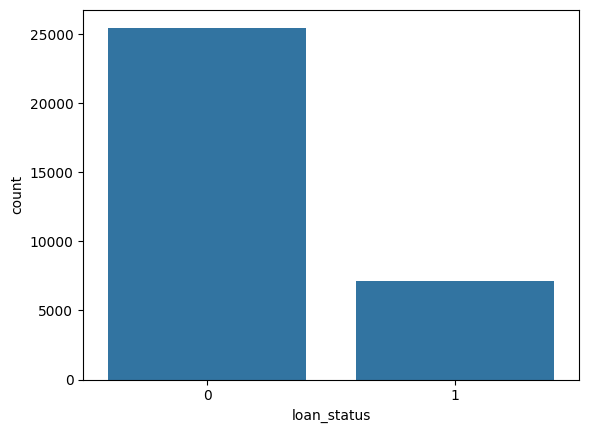

In [6]:
sns.countplot(x='loan_status', data=df)

### Outlier check
- Look for values that seem impossible, like age 144.

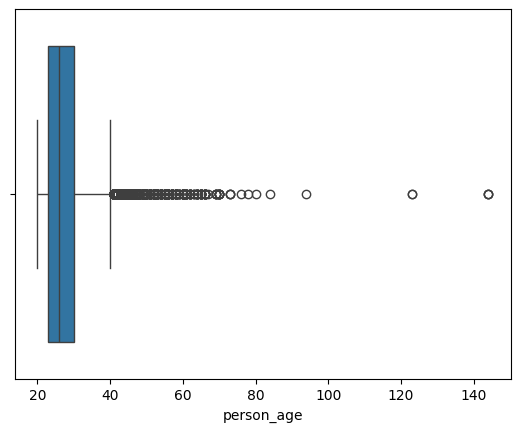

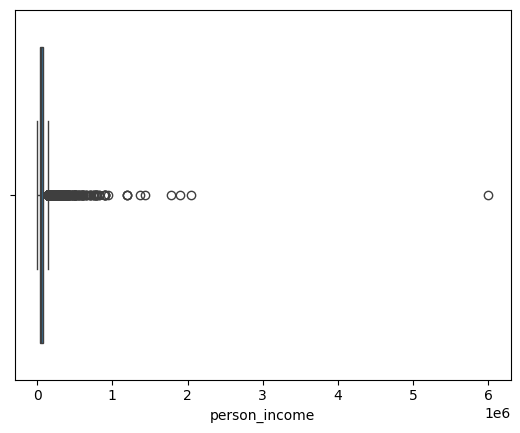

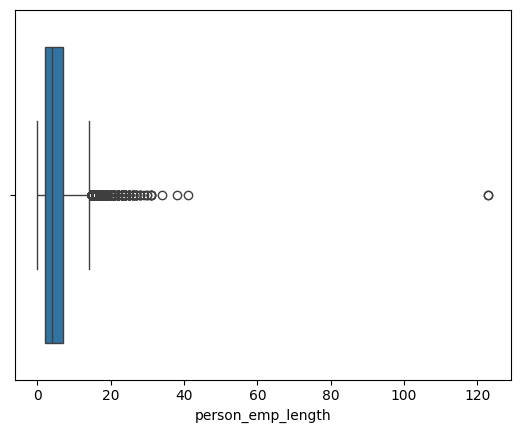

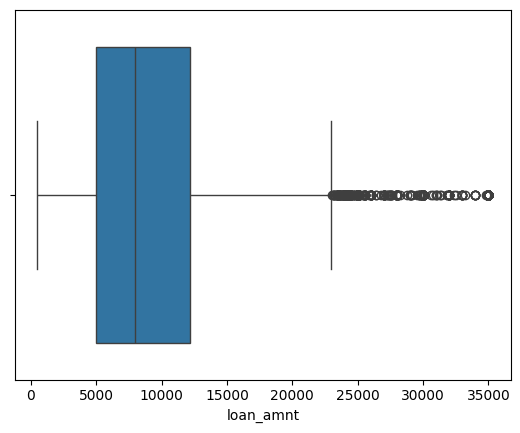

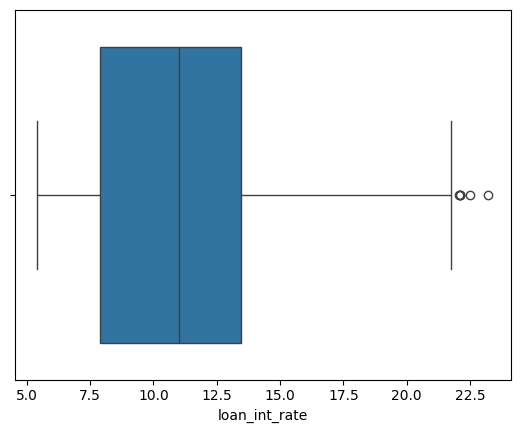

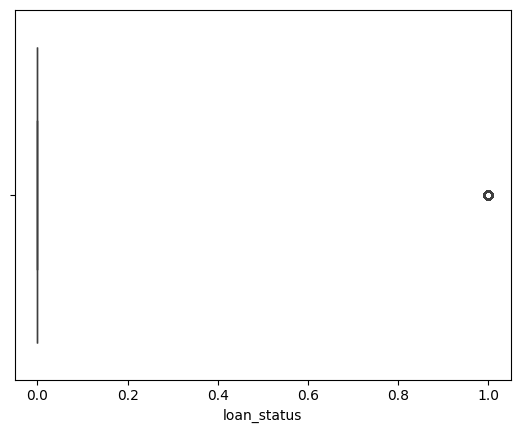

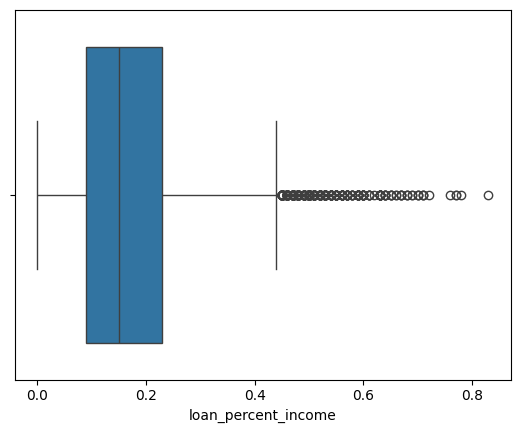

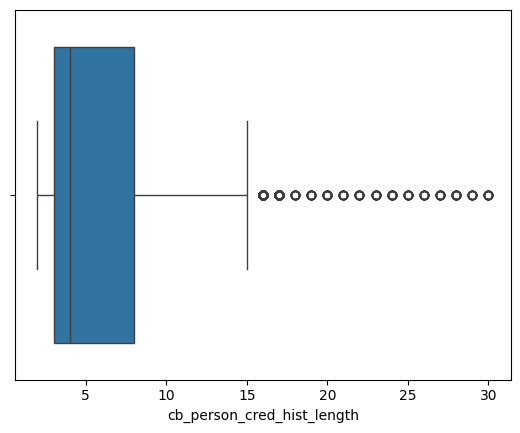

In [7]:
numerical_cols = df.select_dtypes(include=np.number).columns

for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()



In [8]:
(df['person_age'] > 100).sum()

np.int64(5)

In [9]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

In [10]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


### Correlation check
- See how strongly features are related to each other.


<Axes: >

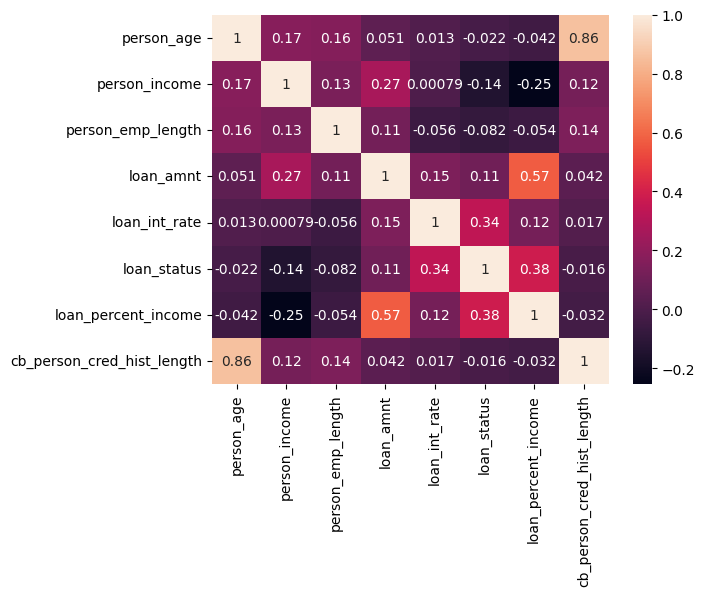

In [ ]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## 3. Data Validation & Outlier Handling
- Clean the data properly.
- Remove duplicate rows.
- Remove rows with an impossible age or work experience.
- No row with zero or negative income and loan amount.
- Interest rate looks realistic.

In [11]:
df_copy = df.copy()

print(f"Original Rows: {df_copy.shape[0]}")

#Remove Duplicate rows
df_copy = df_copy.drop_duplicates()
print(f"Rows after removing duplicates : {df_copy.shape[0]}")

#Remove ages below 18 or below 100
df_copy = df_copy[df_copy['person_age'] >=18]
df_copy = df_copy[df_copy['person_age'] <= 100]

#Remove employment length greater than age or extreme outliers (>60)
df_copy = df_copy[df_copy['person_emp_length'] < df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]

#Interest rate looks realistic.
print("Loan intreset rate range from (min: 5.42 and max: 23.22)")

Original Rows: 32581
Rows after removing duplicates : 32416
Loan intreset rate range from (min: 5.42 and max: 23.22)


## 4. Features, Target & Train-Test Split
- We separate the data into input features and the target.
- The target is whether the applicant defaulted or not.
- We split the data into a training part and a testing part.
- The model learns from the training part only.

In [ ]:
X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status'] #0,1

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

## 5. Handle Class Imbalance
- Very few people actually default in this data.
- If we ignore this, the model may just favor the majority class.
- So we have to assign higher weights to the minority class during training to heavily penalize misclassifications.
- This helps the model actually learn to spot defaulters.

In [ ]:
#0 -> repaid (most)
#1 -> default

neg, pos = np.bincount(y_train)

scale_weigths = neg/pos * 1.5

In [ ]:
scale_weigths

np.float64(5.446831955922865)

## 6. Data Preprocessing — Pipelines & Column Transformer
- Raw data is not ready for a model directly.
- We need to prepare numeric and text columns differently.
- We will build a Pipeline for each model.
- We will use ColumnTransformer to apply different steps to different columns.

### Preprocessing for Logistic Regression
- Fill missing numeric values.
- Scale numeric values, since this model is sensitive to scale.
- Convert category columns into numbers using one-hot encoding.

In [ ]:
#Logistic Regression : impute + SCALE Numeric, impute + One-Hot-Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


### Preprocessing for XGBoost
- Fill missing numeric values.
- No scaling needed here, since tree models don't need it.
- Convert category columns into numbers using one-hot encoding.

In [ ]:
#XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


## 7. Evaluation Helper Function
- We are building one common function to check any model's performance.
- It will show accuracy, precision, recall, F1 score.
- It will also show a confusion matrix, classification_report and a precision-recall curve.

In [12]:
#We have to evaluate Logistic Model and XGBoost model on the basis of their metrics

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,roc_auc_score, confusion_matrix, classification_report, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold is not None:
    y_pred = (y_pred_prob >= threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  #Metrics
  accuracy     = accuracy_score(y_test, y_pred)
  precision    = precision_score(y_test, y_pred)
  recall       = recall_score(y_test, y_pred)
  f1           = f1_score(y_test, y_pred)
  roc_auc      = roc_auc_score(y_test,y_pred_prob)
  conf_matrix   = confusion_matrix(y_test, y_pred)
  class_report  = classification_report(y_test, y_pred)


  print(f"{model_name} Metrics:")
  if threshold is not None: # Only print threshold if provided
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall : {recall:.2f}")
  print(f"F1 : {f1:.2f}")
  print(f"roc_auc : {roc_auc:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)


  #Plotting confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()


  #Plotting ROC-AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

## 8. Stratified Cross-Validation
- One single train-test split may not be reliable.
- We split the training data into three folds instead.
- Each fold keeps the same default vs repaid ratio.
- We check the model's score across all folds.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [ ]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [ ]:
import pip
!pip install xgboost
#XGboost Model
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimator=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weigths,random_state=42
    ))
])

In [ ]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train , y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC-AUC : {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
                      print(f"Precision : {cv_results['test_precision'].mean()}")
                      print(f"Recall : {cv_results['test_recall'].mean()}")
                      print(f"F1 : {cv_results['test_f1'].mean()}")
                      print()

Logistic Regression
ROC-AUC : 0.8704143759896482
Accuracy : 0.8112778947117129
Precision : 0.5441416115410139
Recall : 0.7786960514233242
F1 : 0.6405692239172943

XGBoost
ROC-AUC : 0.9380950664786672
Accuracy : 0.8757183487295955
Precision : 0.6729306314776607
Recall : 0.8293847566574839
F1 : 0.7426181628241522



## 9. Baseline Model — Logistic Regression
- We start with a simple model first.
- This becomes our benchmark to beat.
- We train it and check its score on the test data.

In [ ]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight= "balanced"))
])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

In [ ]:
#Evaluate the Logistic Model.

Baseline Logistic Model Metrics:
Accuracy : 0.82
Precision : 0.56
Recall : 0.79
F1 : 0.65
roc_auc : 0.88

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



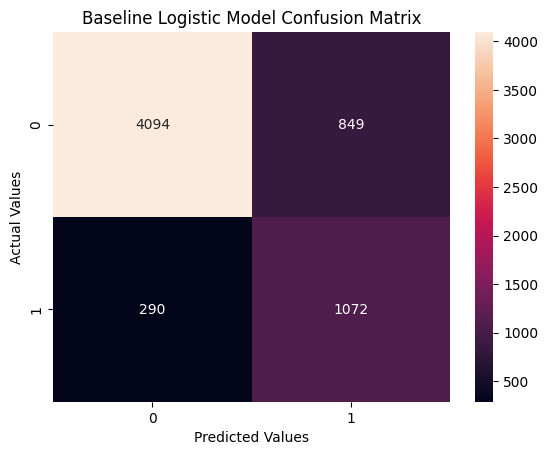

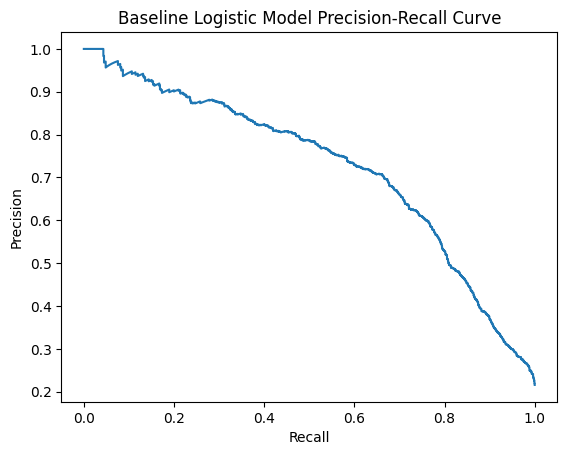

In [ ]:
evaluate_model("Baseline Logistic Model", baseline_model ,X_test, y_test)

## 10. XGBoost Hyperparameter Tuning
- Now we move to a stronger model, XGBoost.
- A model has many settings called hyperparameters.
- We search for the best combination of these settings.
- We use cross-validation while searching, so the result is reliable.

In [ ]:
#creating a base model for xgboost
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1,
        scale_pos_weight=scale_weigths,random_state=42))
])
xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [ ]:
#Hyper parameter tunning
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 800),
    "classifier__max_depth" : randint(3,8),
    "classifier__learning_rate" : uniform(0.01, 0.3),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}

In [ ]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="recall",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 150 candidates, totalling 450 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e48d8d24cd0>,
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e48d8d25310>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e48d1bafe00>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7e48d8d24f50>},
                   scoring='recall', verbose=1)

In [ ]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

Score after performing Tunning 0.84


In [ ]:
#Get the best hyperparameters
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.9792075276522005),
 'classifier__gamma': np.float64(3.2506906614194033),
 'classifier__learning_rate': np.float64(0.07376715412437487),
 'classifier__max_depth': 3,
 'classifier__min_child_weight': 1,
 'classifier__n_estimators': 432,
 'classifier__subsample': np.float64(0.7121451530188869)}

In [ ]:
# Get the best cross-validation score
print(random_search.best_score_)

0.8433425160697888


In [ ]:
# Get the best trained pipeline
best_xgb_model = random_search.best_estimator_

## 11. Compare Both Models Side by Side
- We now compare Logistic Regression and XGBoost.
- We look at their scores together in one table.
- This helps us pick the better performing model.

Logistic Regression Metrics:
Accuracy : 0.82
Precision : 0.56
Recall : 0.79
F1 : 0.65
roc_auc : 0.88

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



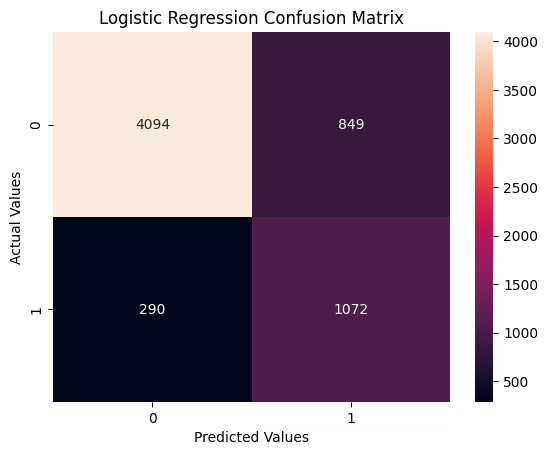

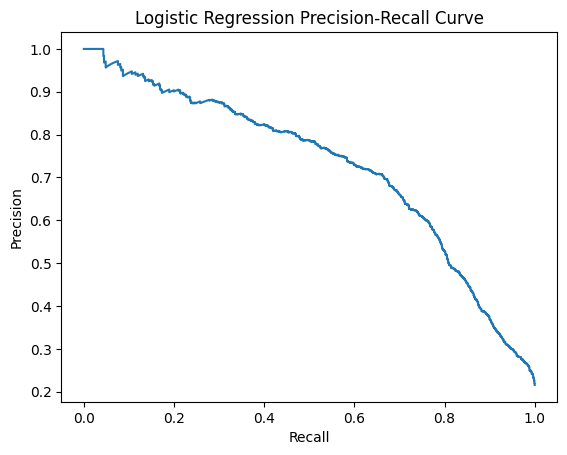

In [ ]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

XGBoost Metrics:
Accuracy : 0.88
Precision : 0.66
Recall : 0.85
F1 : 0.75
roc_auc : 0.95

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.88      0.92      4943
           1       0.66      0.85      0.75      1362

    accuracy                           0.88      6305
   macro avg       0.81      0.87      0.83      6305
weighted avg       0.89      0.88      0.88      6305



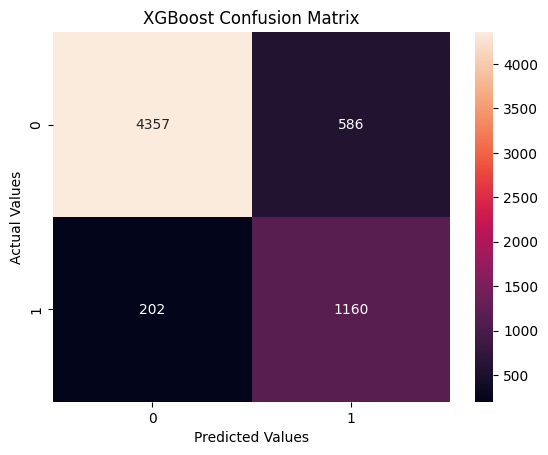

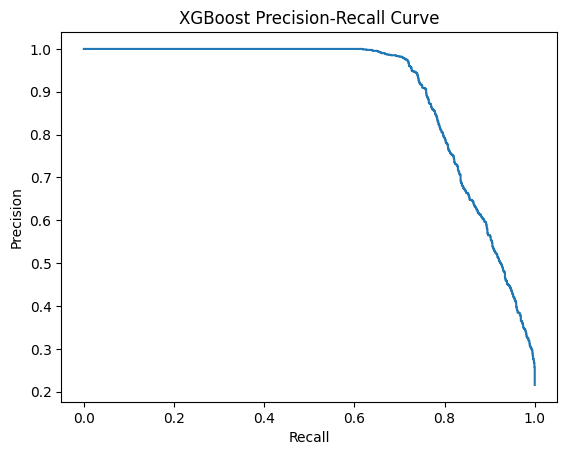

In [ ]:
#Passing the XGBoost model after performing Hyperparameter Tuning
evaluate_model("XGBoost", best_xgb_model, X_test, y_test)

## 12. Probability Calibration
- Sometimes a model's probability doesn't match the actual results.
- We check this with a calibration plot.
- We fix it if the probabilities are off.

In [ ]:
#1. Calibrated XGBoost model using Isotonic Method
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_xgb_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_xgb_model,
    method="isotonic",
    cv=5
)

calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.07376715412437487),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=3,
                                                                max_leaves=None,
                                                                min_child_weight=1,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=432,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]),
                       method='isotonic')

In [ ]:
#2. Get probabilites
uncalibrated = best_xgb_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [ ]:
#3. create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)

In [ ]:
actual_cal, predicted_cal  = calibration_curve(y_test, calibrated, n_bins=10)

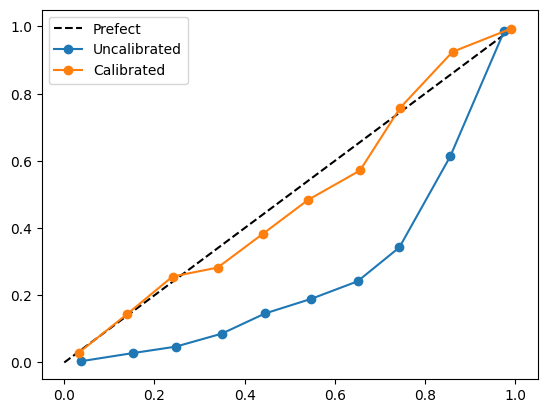

In [ ]:
#4. plot
plt.plot([0,1], [0,1], 'k--', label="Prefect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)
plt.legend()

XGBoost Metrics:
Accuracy : 0.93
Precision : 0.96
Recall : 0.73
F1 : 0.83
roc_auc : 0.95

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.96      0.73      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.94      0.86      0.89      6305
weighted avg       0.94      0.93      0.93      6305



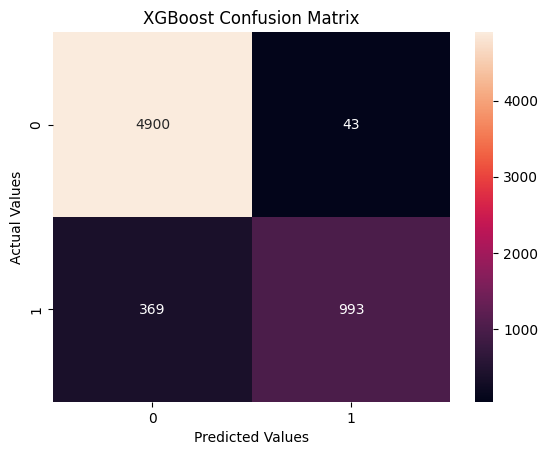

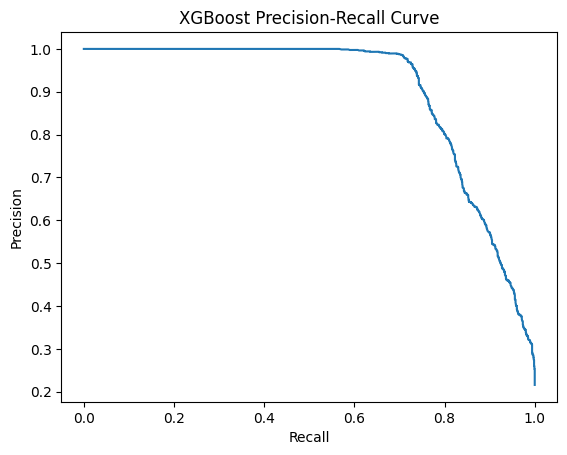

In [ ]:
#Passing the XGBoost model after performing Hyperparameter Tuning and Probablity Calilberation
evaluate_model("XGBoost", calibrated_model, X_test, y_test)

## 13. Optimizing the Classification Threshold
- The model gives a probability, not a direct labeled decision.
- We decide a cut-off point to turn it into a decision.
- We check different cut-off points and pick the best one.

Optimal Threshold (found via OOF Training Data): 0.2032
OOF Expected Precision : 0.740
OOF Expected Recall    : 0.810

XGBoost (Optimized OOF) Metrics:
Used Threshold : 0.20
Accuracy : 0.90
Precision : 0.75
Recall : 0.82
F1 : 0.79
roc_auc : 0.95

XGBoost (Optimized OOF) Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      4943
           1       0.75      0.82      0.79      1362

    accuracy                           0.90      6305
   macro avg       0.85      0.87      0.86      6305
weighted avg       0.91      0.90      0.90      6305



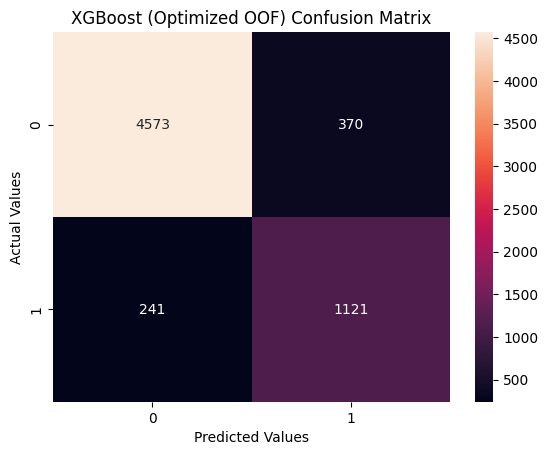

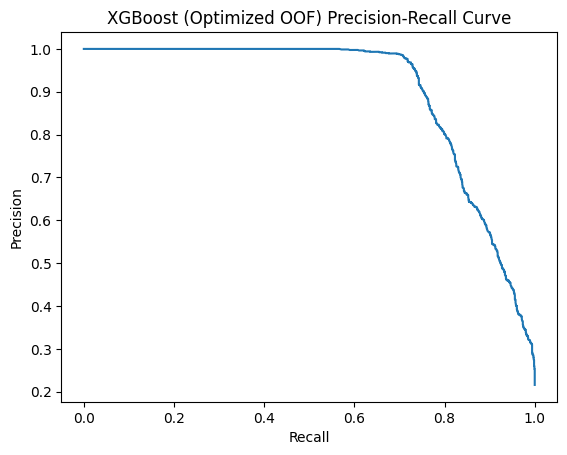

In [ ]:
# 13. Optimizing the Classification Threshold (OOF Method)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import CalibratedClassifierCV
import numpy as np

# 1. We need out-of-fold (OOF) probabilities on the TRAINING set to avoid data leakage.
deploy_spec = CalibratedClassifierCV(best_xgb_model, method="isotonic", cv=5)

oof_prob = cross_val_predict(
    deploy_spec,
    X_train, y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

# 2. Compute precision-recall curve on the OOF training predictions
oof_prec, oof_rec, oof_thr = precision_recall_curve(y_train, oof_prob)

# 3. Define our business requirement (74% Minimum Precision)
MIN_PRECISION = 0.74

# 4. Find the threshold with the highest recall that meets the 74% precision floor
meets_floor = oof_prec[:-1] >= MIN_PRECISION
best_idx = np.where(meets_floor)[0][np.argmax(oof_rec[:-1][meets_floor])]
best_threshold = oof_thr[best_idx]

print(f"Optimal Threshold (found via OOF Training Data): {best_threshold:.4f}")
print(f"OOF Expected Precision : {oof_prec[:-1][best_idx]:.3f}")
print(f"OOF Expected Recall    : {oof_rec[:-1][best_idx]:.3f}\n")

# 5. Evaluate the final calibrated_model on the TEST set using this frozen threshold
evaluate_model("XGBoost (Optimized OOF)", calibrated_model, X_test, y_test, best_threshold)

## 14. SHAP Interpretation — Global & Local
- SHAP helps us understand why the model makes a decision.
- It is a way of explaining a "black box" model.

In [ ]:
#1. Install SHAP if not exists
!pip install shap
import shap

In [ ]:
#2. Get the Trained XGBoost classifier model out of the pipeline.
xgb_classifier = best_xgb_model.named_steps['classifier']

In [ ]:
#3. Transform X_test using the same preprocessing used for training.
X_test_transformed = best_xgb_model.named_steps['preprocessor'].transform(X_test)

In [ ]:
#4. Get feature names after one-hot enocding , so plots are readable
feature_names = best_xgb_model.named_steps['preprocessor'].get_feature_names_out()

In [ ]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [ ]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [ ]:
#7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-3.5734460e-02,  2.5499916e-01,  3.3104685e-01, ...,
        -9.8489746e-03, -2.0663443e-03, -7.0145784e-04],
       [-3.1859979e-02, -9.2337608e-01, -5.2153539e-02, ...,
        -1.0280679e-02, -2.6985437e-03, -7.0145784e-04],
       [ 6.1219625e-02,  3.7628384e+00,  1.1187734e-01, ...,
        -1.0035865e-02, -2.0663443e-03, -7.0145784e-04],
       ...,
       [-9.0978602e-03,  5.1563716e-01,  8.7280951e-02, ...,
        -1.0230005e-02, -2.8279268e-03, -7.0145784e-04],
       [ 2.9575951e-02, -9.4255680e-01,  1.4511825e-01, ...,
        -1.0217484e-02, -1.3727332e-02, -2.8333799e-03],
       [-3.1741604e-02, -9.6957922e-01,  3.4185026e-02, ...,
        -1.0036098e-02, -8.6850738e-03, -7.0145784e-04]],
      shape=(6305, 26), dtype=float32)

### Global explanation
- This shows which features matter most overall.
- It also shows if a feature increases or decreases risk.

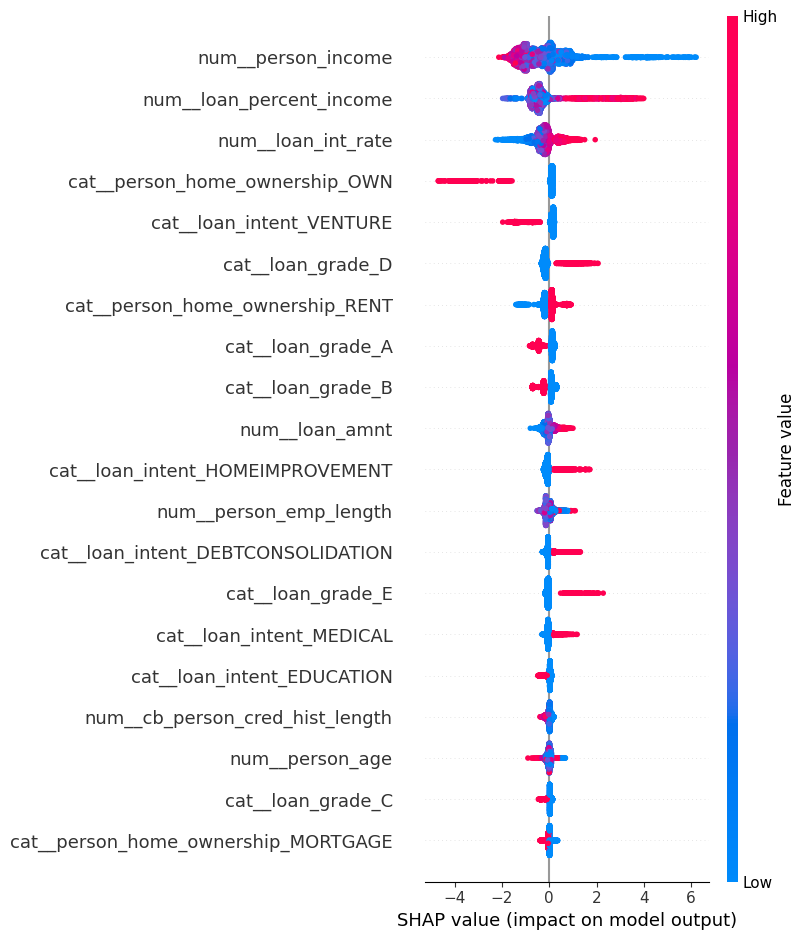

In [ ]:
shap.summary_plot(shap_values, X_test_df)

### Local explanation
- This shows why one specific applicant got their score.
- It breaks the score down feature by feature.

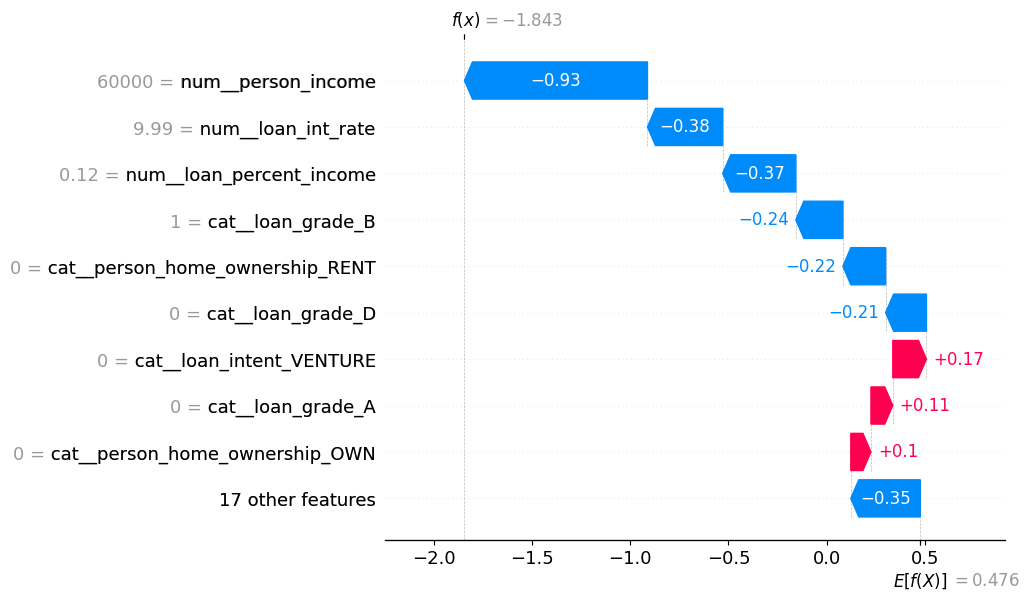

In [ ]:
# 1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

## 15. Analyzing False Positives & False Negatives
- The model will not be perfect.
- False positives are safe people wrongly marked risky.
- False negatives are risky people wrongly marked safe.
- We study these cases to understand where the model struggles.

In [ ]:
# 15. Analyzing False Positives & False Negatives (Deployed Model)

# 1. Get probabilities from the final deployed model
test_probs = calibrated_model.predict_proba(X_test)[:, 1]

# 2. Apply your optimized business threshold (not the default 0.5)
y_pred_optimal = (test_probs >= best_threshold).astype(int)

# 3. Create a dataframe to compare actuals vs your threshold predictions
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred_optimal

# 4. Identify False Positives & False Negatives
false_positives = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]
false_negatives = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]

print(f"False Positives (Good customers wrongly rejected) : {len(false_positives)}")
print(f"False Negatives (Defaulters wrongly approved)     : {len(false_negatives)}")

False Positives (Good customers wrongly rejected) : 370
False Negatives (Defaulters wrongly approved)     : 241


In [ ]:
#False Positive > False Negative comapred to earlier models where False Negatives were more than False Positives

## 16. Save the Final Model
- Once we are satisfied with the model, we save it.
- We also save the settings it needs, like the chosen threshold.
- This saved file can now be used in a real application.

In [ ]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model_final.pkl")

['credit_risk_model_final.pkl']

In [ ]:
joblib.dump(best_threshold, "best_threshold_final.pkl")

['best_threshold_final.pkl']